In [5]:
import calendar
import re
import os
import subprocess

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Import table with metadata for all GenBank entries assigned as Astroviridae (obtained from https://github.com/v-julia/Astroviridae_database)

In [2]:
astro_meta = pd.read_csv("D:/Virology/RNA_viruses/Astrovirus/Astroviridae_database/data/results/30-06-2026/final/Astroviridae_30062026_annotated_MAstV_species.tsv", sep="\t")

C:\Users\Администратор\AppData\Local\Temp\ipykernel_18992\3804627669.py:1: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  astro_meta = pd.read_csv("D:/Virology/RNA_viruses/Astrovirus/Astroviridae_database/data/results/30-06-2026/final/Astroviridae_30062026_annotated_MAstV_species.tsv", sep="\t")


In [3]:
astro_meta.shape

(16448, 40)

In [4]:
astro_meta.columns

Index(['Accession', 'LOCUS', 'Version', 'GenBank title', 'Release date',
       'Organism name', 'Virus Lineage', 'Species', 'Family', 'Length',
       'Reference_title', 'Submitters', 'PUBMED_ID', 'Strain', 'Isolate',
       'Geo location', 'Country', 'Collection date', 'Tissue/Specimen/Source',
       'Host', 'Environmental', 'CDS count', 'Artificial', 'UNVERIFIED', '1A',
       '1A-strand', '1B', '1B-strand', '2', '2-strand', 'host_clean',
       'Host_species', 'Host_genus', 'Host_family', 'Host_order', 'Host_class',
       'Host_phylum', 'Host_kingdom', 'Species_ICTV', 'virus_name'],
      dtype='object')

Leave genbank accessions that have annotations for all the three ORFs

In [5]:
astro_meta_full = astro_meta[astro_meta['1A-strand'].notna() & astro_meta['1B-strand'].notna() & astro_meta['2-strand']]

Check the distribution of genome lengths

In [6]:
astro_meta_full["Length"].describe()

count    1761.000000
mean     6569.409426
std       671.431865
min      2163.000000
25%      6334.000000
50%      6625.000000
75%      6928.000000
max      8417.000000
Name: Length, dtype: float64

<Axes: >

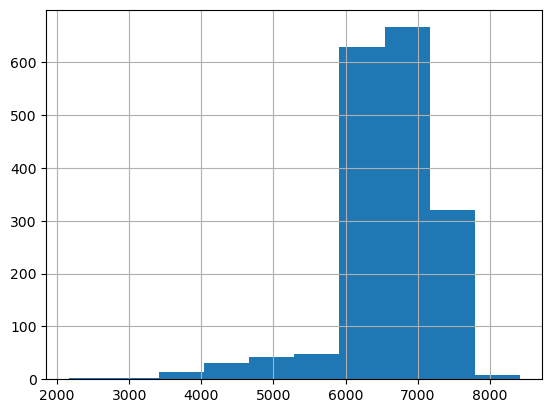

In [7]:
astro_meta_full["Length"].hist()

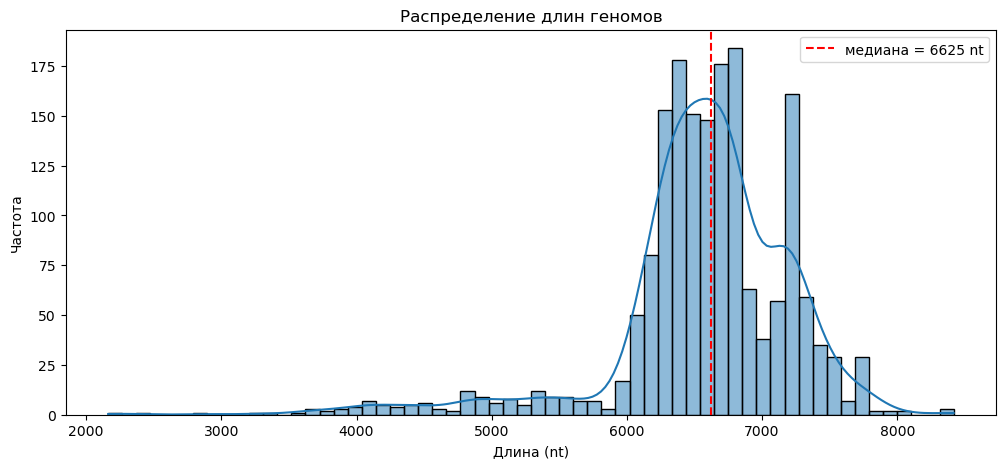

In [18]:
plt.figure(figsize=(12, 5))
sns.histplot(astro_meta_full['Length'], bins=60, kde=True)
plt.axvline(astro_meta_full['Length'].median(), color='red', linestyle='--', label=f'медиана = {astro_meta_full['Length'].median():.0f} nt')
plt.title('Распределение длин геномов')
plt.xlabel('Длина (nt)')
plt.ylabel('Частота')
plt.legend()
plt.show()
     

The entries with genome lengths less that 6000 seem to have incomplete CDS.
Since we need to check the RBS, we can leave the genomes with shorter ORF1a or ORF2

In [19]:
astro_meta_full[(astro_meta_full["Length"]>5000) & (astro_meta_full["Length"]<5600)]

,Accession,LOCUS,Version,GenBank title,Release date,Organism name,Virus Lineage,Species,Family,Length,...,host_clean,Host_species,Host_genus,Host_family,Host_order,Host_class,Host_phylum,Host_kingdom,Species_ICTV,virus_name
245,LC900477,LC900477,LC900477.1,MAG: Porcine astrovirus 2 PoAstV-2/wt/Pig/Japa...,11-NOV-2025,Porcine astrovirus 2,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5540,...,Sus scrofa,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Chordata,Metazoa,NaN,NaN
246,LC900476,LC900476,LC900476.1,MAG: Porcine astrovirus 4 PoAstV-4/wt/Pig/Japa...,11-NOV-2025,Porcine astrovirus 4,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,Mamastrovirus suisvulgaris,Astroviridae,5146,...,Sus scrofa,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Chordata,Metazoa,NaN,NaN
317,LC900360,LC900360,LC900360.1,MAG: Porcine astrovirus 2 PoAstV-2/wt/Wild_Boa...,11-NOV-2025,Porcine astrovirus 2,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5565,...,Sus scrofa,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Chordata,Metazoa,NaN,NaN
321,LC900343,LC900343,LC900343.1,MAG: Porcine astrovirus 2 PoAstV-2/wt/Wild_Boa...,11-NOV-2025,Porcine astrovirus 2,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5051,...,Sus scrofa,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Chordata,Metazoa,NaN,NaN
477,PX236817,PX236817,PX236817.1,Possum astrovirus isolate M22 ORF1a protein an...,24-SEP-2025,Possum astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5446,...,Trichosurus vulpecula,Trichosurus vulpecula,Trichosurus,Phalangeridae,Diprotodontia,Mammalia,Chordata,Metazoa,NaN,NaN
540,OR951045,OR951045,OR951045.1,MAG: Bat astrovirus isolate GD2017_207_27658 s...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5500,...,Myotis pilosus,Myotis pilosus,Myotis,Vespertilionidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
551,OR951034,OR951034,OR951034.1,MAG: Bat astrovirus isolate GD2017_191_26815 s...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5439,...,Hipposideros larvatus,Hipposideros larvatus,Hipposideros,Hipposideridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
1078,PP871791,PP871791,PP871791.1,MAG: Mamastrovirus sp. isolate astro_vt_73 gen...,14-JUN-2025,Mamastrovirus sp.,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5317,...,Sus scrofa domesticus,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Chordata,Metazoa,NaN,MAstV32*
1111,PP871758,PP871758,PP871758.1,MAG: Mamastrovirus sp. isolate astro_vt_40 gen...,14-JUN-2025,Mamastrovirus sp.,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5181,...,Sus scrofa,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Chordata,Metazoa,Mamastrovirus suisvulgaris,MAstV26*
1363,PQ541178,PQ541178,PQ541178.1,MAG: Murine astrovirus isolate Mu. setulosus_a...,20-FEB-2025,Murine astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,5436,...,Mus setulosus,Mus setulosus,Mus,Muridae,Rodentia,Mammalia,Chordata,Metazoa,NaN,NaN


In [9]:
astro_meta_full = astro_meta_full[astro_meta_full["Length"]>5000]

In [10]:
astro_meta_full.shape

(1693, 40)

In [11]:
astro_meta_full.columns

Index(['Accession', 'LOCUS', 'Version', 'GenBank title', 'Release date',
       'Organism name', 'Virus Lineage', 'Species', 'Family', 'Length',
       'Reference_title', 'Submitters', 'PUBMED_ID', 'Strain', 'Isolate',
       'Geo location', 'Country', 'Collection date', 'Tissue/Specimen/Source',
       'Host', 'Environmental', 'CDS count', 'Artificial', 'UNVERIFIED', '1A',
       '1A-strand', '1B', '1B-strand', '2', '2-strand', 'host_clean',
       'Host_species', 'Host_genus', 'Host_family', 'Host_order', 'Host_class',
       'Host_phylum', 'Host_kingdom', 'Species_ICTV', 'virus_name'],
      dtype='object')

In [12]:
user_cols = ['Organism name', 'Species', 'Geo location', 'Country', 'Collection date', 'Tissue/Specimen/Source',
       'Host', 'Environmental', 'CDS count', 'host_clean',
       'Host_species', 'Host_genus', 'Host_family', 'Host_order', 'Host_class',
       'Species_ICTV']   # specify your columns
astro_meta_full[user_cols].describe(include=['object', 'category'])

,Organism name,Species,Geo location,Country,Collection date,Tissue/Specimen/Source,Host,Environmental,host_clean,Host_species,Host_genus,Host_family,Host_order,Host_class,Species_ICTV
count,1693,450,1609,1609,1507,1090,1547,1693,1547,1507,1522,1524,1531,1534,520
unique,285,24,152,47,533,100,244,2,172,143,118,73,34,9,17
top,Goose astrovirus,Mamastrovirus hominis,China,CHN,2021,feces,Homo sapiens,No,Sus scrofa,Sus scrofa,Sus,Suidae,Artiodactyla,Mammalia,Mamastrovirus hominis
freq,204,150,625,852,88,381,203,1212,303,336,336,336,514,1082,164


In [13]:
for col in user_cols:
    print(f"\n--- {col} ---")
    print(astro_meta_full[col].value_counts(dropna=False))


--- Organism name ---
Goose astrovirus            204
Bovine astrovirus            94
Porcine astrovirus 2         75
Canine astrovirus            71
Chicken astrovirus           64
                           ... 
Xinjiang mamastrovirus 5      1
Xinjiang mamastrovirus 1      1
Hubei mamastrovirus 4         1
Hubei mamastrovirus 1         1
Astrovirus SG                 1
Name: Organism name, Length: 285, dtype: int64

--- Species ---
NaN                                      1243
Mamastrovirus hominis                     150
Mamastrovirus suisvulgaris                 58
Mamastrovirus suisorientalis               55
Mamastrovirus felis                        40
Mamastrovirus suisencephalomyelitidis      36
Avastrovirus intestini                     30
Mamastrovirus melbournense                 15
Duck astrovirus GII.A                      14
Mamastrovirus ovis                         11
Mamastrovirus bovisencephalitidis          10
Mamastrovirus virginiaense                  6
Avastrovi

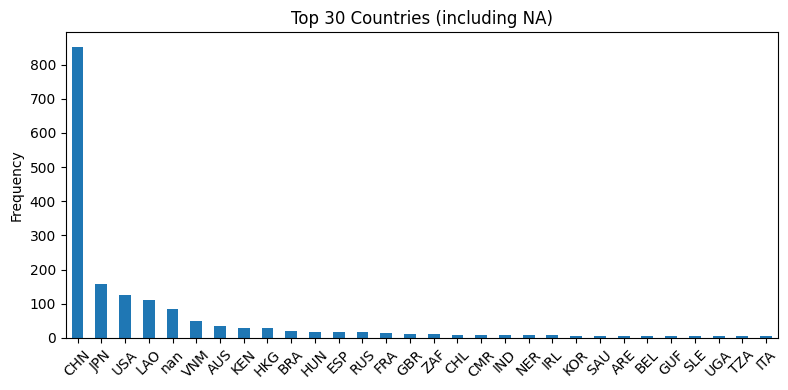

In [14]:
astro_meta_full['Country'].value_counts(dropna=False).head(30).plot(
    kind='bar',
    rot=45,                # Rotates x-axis labels 45 degrees
    figsize=(8, 4)
)
plt.title('Top 30 Countries (including NA)')
plt.ylabel('Frequency')
plt.tight_layout()         # Prevents label clipping
plt.show()

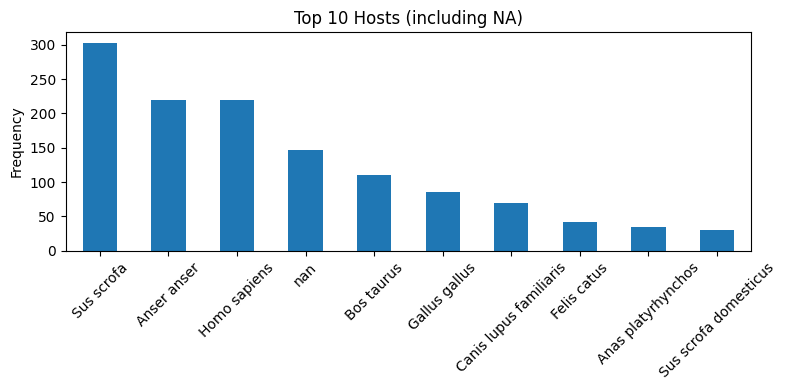

In [15]:
astro_meta_full['host_clean'].value_counts(dropna=False).head(10).plot(
    kind='bar',
    rot=45,                # Rotates x-axis labels 45 degrees
    figsize=(8, 4)
)
plt.title('Top 10 Hosts (including NA)')
plt.ylabel('Frequency')
plt.tight_layout()         # Prevents label clipping
plt.show()

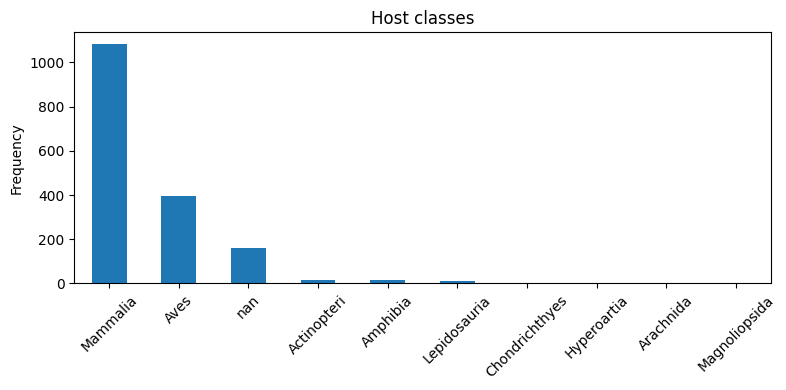

In [16]:
astro_meta_full['Host_class'].value_counts(dropna=False).plot(
    kind='bar',
    rot=45,                # Rotates x-axis labels 45 degrees
    figsize=(8, 4)
)
plt.title('Host classes')
plt.ylabel('Frequency')
plt.tight_layout()         # Prevents label clipping
plt.show()

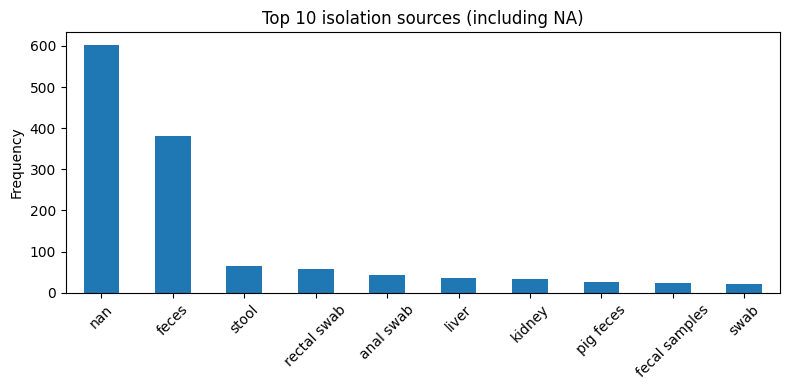

In [17]:
astro_meta_full['Tissue/Specimen/Source'].value_counts(dropna=False).head(10).plot(
    kind='bar',
    rot=45,                # Rotates x-axis labels 45 degrees
    figsize=(8, 4)
)
plt.title('Top 10 isolation sources (including NA)')
plt.ylabel('Frequency')
plt.tight_layout()         # Prevents label clipping
plt.show()

# Distribution of ORF lengths

In [20]:
for col in ["1B", "1A", "2"]:
    parts = astro_meta_full[col].str.split('-', expand=True)
    astro_meta_full[f"{col}_length"] = parts[1].astype(int) - parts[0].astype(int) + 1

C:\Users\Администратор\AppData\Local\Temp\ipykernel_18992\125364032.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  astro_meta_full[f"{col}_length"] = parts[1].astype(int) - parts[0].astype(int) + 1
C:\Users\Администратор\AppData\Local\Temp\ipykernel_18992\125364032.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  astro_meta_full[f"{col}_length"] = parts[1].astype(int) - parts[0].astype(int) + 1
C:\Users\Администратор\AppData\Local\Temp\ipykernel_18992\125364032.py:3: SettingWithCopyWarning: 
A value

## ORF1b sequences

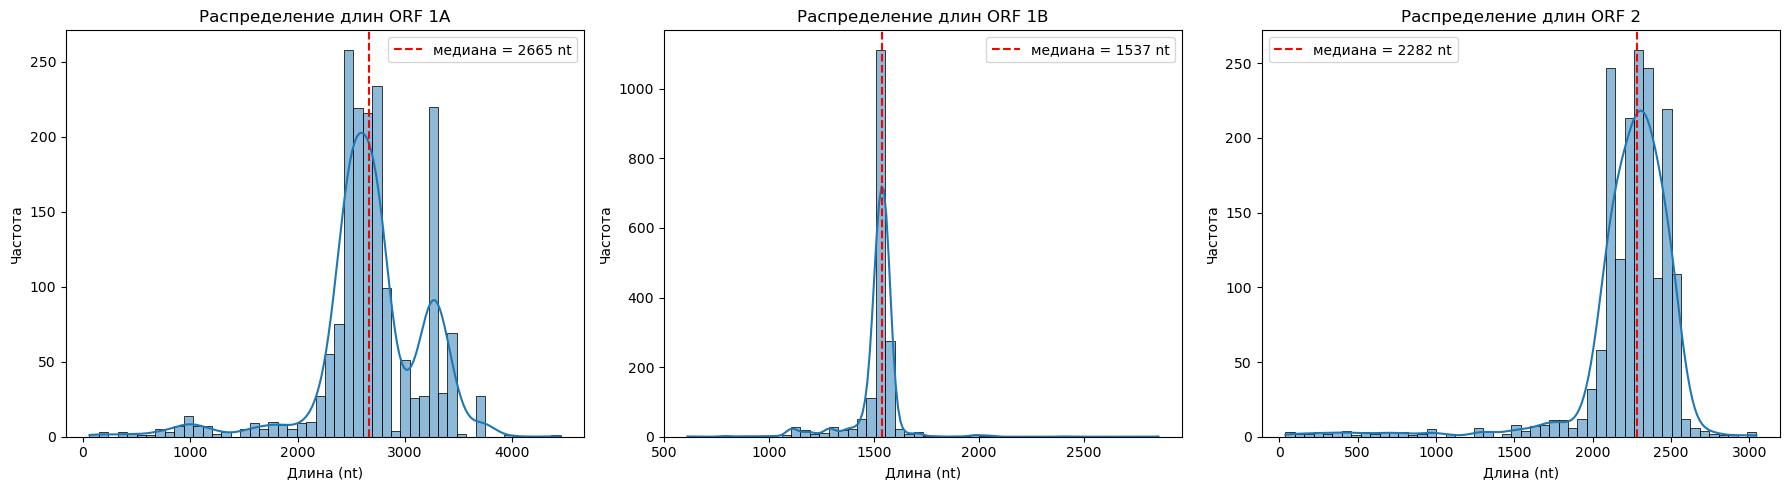

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, orf in enumerate(['1A', '1B', '2']):
    sns.histplot(astro_meta_full[f'{orf}_length'], bins=50, kde=True, ax=axes[i])
    median = astro_meta_full[f'{orf}_length'].median()
    axes[i].axvline(median, color='red', linestyle='--',
                    label=f'медиана = {median:.0f} nt')
    axes[i].set_title(f'Распределение длин ORF {orf}')
    axes[i].set_xlabel('Длина (nt)')
    axes[i].set_ylabel('Частота')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [20]:
astro_meta_full[astro_meta_full["1B_length"] < 1000][["Accession", "GenBank title", "1A", "1B", "2", "1A_length", "1B_length", "2_length"]]

,Accession,GenBank title,1A,1B,2,1A_length,1B_length,2_length
555,OR951030,MAG: Bat astrovirus isolate GD2016_189_12430 s...,182-2105,2104-3040,3659-5858,1924,937,2200
1214,PV351771,Astroviridae sp. isolate HN_K2f_303 Non-struct...,6-2775,3431-4223,4179-6738,2770,793,2560
1362,PQ541179,MAG: Rat mamastrovirus isolate Pr. rostratus_a...,9-2781,3296-4265,4179-6863,2773,970,2685
1365,PQ541164,MAG: Rat mamastrovirus isolate Ma. erythroleuc...,9-2781,3395-4265,4116-6830,2773,871,2715
1411,PQ678014,MAG: Yunnan rodent mamastrovirus 4 isolate YNM...,38-2705,3361-4153,4109-6638,2668,793,2530
1417,PQ678008,MAG: Jingmen rodent astrovirus 2 isolate DQWX-...,4-2779,3435-4227,4183-6712,2776,793,2530
1987,PP711869,MAG: Cardioderma bat astrovirus isolate 26A/Ke...,0-2799,2807-3509,3465-5895,2800,703,2431
1992,PP711864,MAG: Coleura bat astrovirus isolate 19A/Kenya/...,913-2704,3319-4207,4203-6361,1792,889,2159


At this step I decide to delete entries with short ORF1b after looking at the alignment

In [71]:
astro_meta_full[astro_meta_full["1B_length"] > 1050]

,Accession,LOCUS,Version,GenBank title,Release date,Organism name,Virus Lineage,Species,Family,Length,...,Host_family,Host_order,Host_class,Host_phylum,Host_kingdom,Species_ICTV,virus_name,1B_length,1A_length,2_length
0,PZ195463,PZ195463,PZ195463.1,"Goose astrovirus isolate G29, complete genome",23-JUN-2026,Goose astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,7116,...,Phasianidae,Galliformes,Aves,Chordata,Metazoa,NaN,NaN,1288,3256,2116
1,PZ195462,PZ195462,PZ195462.1,"Goose astrovirus isolate X-1, complete genome",23-JUN-2026,Goose astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,7116,...,Anatidae,Anseriformes,Aves,Chordata,Metazoa,NaN,NaN,1288,3256,2116
2,PZ195461,PZ195461,PZ195461.1,"Goose astrovirus isolate G292, complete genome",23-JUN-2026,Goose astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,7116,...,Anatidae,Anseriformes,Aves,Chordata,Metazoa,NaN,NaN,1288,3256,2116
3,PZ195460,PZ195460,PZ195460.1,"Goose astrovirus isolate G259, complete genome",23-JUN-2026,Goose astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,7116,...,Anatidae,Anseriformes,Aves,Chordata,Metazoa,NaN,NaN,1288,3256,2116
4,PZ195459,PZ195459,PZ195459.1,"Goose astrovirus isolate G253, complete genome",23-JUN-2026,Goose astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,7116,...,Anatidae,Anseriformes,Aves,Chordata,Metazoa,NaN,NaN,1288,3256,2116
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16288,GQ891990,GQ891990,GQ891990.1,"Astrovirus SG, complete genome",01-JUN-2010,Astrovirus SG,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,Mamastrovirus virginiaense,Astroviridae,6584,...,Hominidae,Primates,Mammalia,Chordata,Metazoa,Mamastrovirus virginiaense,MAstV9,1570,2659,2278
16408,Z25771,Z25771,Z25771.1,Human astrovirus type 1 genes for capsid prote...,14-NOV-2006,Human astrovirus 1,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,Mamastrovirus hominis,Astroviridae,6813,...,NaN,NaN,NaN,NaN,NaN,Mamastrovirus hominis,MAstV1,1558,2755,2362
16418,AB033998,AB033998,AB033998.1,Avian nephritis virus 1 genes for structural p...,17-MAY-2006,Avian nephritis virus 1,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,Avastrovirus galli,Astroviridae,6927,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1528,3013,2053
16433,Y15937,Y15937,Y15937.2,"Sheep astrovirus, complete genome, genomic RNA",31-MAR-2003,Mamastrovirus 13,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,Mamastrovirus ovis,Astroviridae,6440,...,Bovidae,Artiodactyla,Mammalia,Chordata,Metazoa,Mamastrovirus ovis,MAstV13,1573,2536,2290


Upd: sequences with short ORF2 should be also deleted

In [33]:
astro_meta_full_filterlength = astro_meta_full[(astro_meta_full["2_length"] > 1950) & (astro_meta_full["1B_length"] > 1080)& (astro_meta_full["1A_length"] > 1500)]
astro_meta_full_filterlength.shape

(1593, 43)

In [34]:
astro_meta_full_filterlength.to_csv("data/metadata/Astroviridae_30062026_complete_genomes.tsv", sep="\t", index=False)

At this step I have manually deleted these entries from data/metadata/Astroviridae_30062026_complete_genomes.tsv, because ORF1b sequence is too short relative to others.


OR951030
PP512783 
PQ541164
PQ678008

PQ541164/Ma.-erythroleucus_astro/SLE/2023/Mastomys-erythroleucus/Mammalia

PQ678014/YNMIX-YNSC210/CHN/2022/Rattus-nitidus/Mammalia

KY294673/HAstV-8-RUS-Novosibirsk-NS16-A87-2016/RUS/2016-02-17/Homo-sapiens/Mammalia

# Important paths

In [3]:
root = "D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/"

Generate fasta files with ORF1b sequences

In [36]:
cmd = [
    "python.exe",
    "D:/Virology/RNA_viruses/Astrovirus/Astroviridae_database/scripts/extract_orfs_named.py",
    "--input","D:/Virology/RNA_viruses/Astrovirus/Astroviridae_database/data/raw/Astroviridae_30062026.gb",
    "--coords",f"{root}metadata/Astroviridae_30062026_complete_genomes.tsv",
    "--metadata", f"{root}metadata/Astroviridae_30062026_complete_genomes.tsv",
    "--output_dir", f"{root}orf_fasta",
    "--columns", "Accession,Isolate,Country,Collection date,Host_species,Host_class",
    "--basename", "Astroviridae_complete"#,
#    "--translate"
]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
print(result.stderr)

Written 1593 sequences to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_fasta\Astroviridae_complete_1A.fna
Written 1593 sequences to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_fasta\Astroviridae_complete_1B.fna
Written 1593 sequences to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_fasta\Astroviridae_complete_2.fna
Skipped 14855 records: accession not in coordinate file
Done.




In [37]:
cmd = [
    "python.exe",
    "D:/Virology/RNA_viruses/Astrovirus/Astroviridae_database/scripts/extract_orfs_named.py",
    "--input","D:/Virology/RNA_viruses/Astrovirus/Astroviridae_database/data/raw/Astroviridae_30062026.gb",
    "--coords",f"{root}metadata/Astroviridae_30062026_complete_genomes.tsv",
    "--metadata", f"{root}metadata/Astroviridae_30062026_complete_genomes.tsv",
    "--output_dir", f"{root}orf_fasta",
    "--columns", "Accession,Isolate,Country,Collection date,Host_species,Host_class",
    "--basename", "Astroviridae_complete",
    "--translate"
]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
print(result.stderr)

Written 1593 sequences to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_fasta\Astroviridae_complete_1A.faa
Written 1593 sequences to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_fasta\Astroviridae_complete_1B.faa
Written 1593 sequences to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_fasta\Astroviridae_complete_2.faa
Skipped 14855 records: accession not in coordinate file
Done.

C:\ProgramData\anaconda3\Lib\site-packages\Bio\Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(



# Check presence of ambiguous characters on ORFs

Remove all sequences with ambiguous characters

In [39]:
base = f"{root}orf_fasta"
out_dir = f"{root}orf_noamb"
for ORF in ["1A", "1B", "2"]:
    input_path = f"{base}/Astroviridae_complete_{ORF}.fna"
    cmd = [
        "python.exe",
        "D:/Scripts/resolve_ambiguous/search_amb.py",
        #"D:/Virology/Scripts/resolve_ambiguous/search_amb.py",
        "-input", input_path,
        "-outdir", out_dir
    ]

    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout)
    print(result.stderr)

Number of records in fasta file: 1593
PZ195454/G24/CHN/2024-06-23/Anser-anser/Aves 1
PX848849/176_astro/IRL/2015/Sus-scrofa/Mammalia 178
PX255447/BTY1YZ/LAO/2017-07-04/Homo-sapiens/Mammalia 1
PV793827/AstroviridaeCranefe81/CHN/2024-01/Leucogeranus-leucogeranus/Aves 1
PV544235/UMN_2024/USA/2024/Mus-musculus/Mammalia 42
PV093025/NA/CHN/2023-01-01/Neogale-vison/Mammalia 1
PV093023/NA/CHN/2023-01-01/Neogale-vison/Mammalia 3
PV093022/NA/CHN/2023-01-01/Neogale-vison/Mammalia 2
PV093020/NA/CHN/2023-01-01/Neogale-vison/Mammalia 6
PV093018/NA/CHN/2023-01-01/Neogale-vison/Mammalia 1
PQ525428/Hu-US-2024-Hastv4-CA-RGDS-1188/USA/2024-01/Homo-sapiens/Mammalia 1
OQ802720/WZ_Ra.losea_astro_1/CHN/2016_2017/Rattus-losea/Mammalia 14
OR571426/SDAU2022-3/CHN/2023/Gallus-gallus/Aves 1
OR286521/SDAU2022-2/CHN/2022/Gallus-gallus/Aves 1
OQ870553/It2018/ITA/NA/NA/NA 42
ON382521/GAstV-GD2103/CHN/2021-11-16/Anser-anser/Aves 2
ON205965/AAstv-CHN-Goose-2018/CHN/2018-05/Anser-anser/Aves 1
ON156528/NA/CHN/2022-01-10/

Resolve ambiguous nt

In [44]:
base = f"{root}orf_fasta"


out_dir = f"{root}orf_res_amb"
for ORF in ["1A", "1B", "2"]:
    input_path = f"{base}/Astroviridae_complete_{ORF}.fna"
    
    cmd = [
    "python.exe",
    #"D:/Virology/Scripts/resolve_ambiguous/resolve_ambiguous.py",
    "D:/Scripts/resolve_ambiguous/resolve_ambiguous.py",
    "-input", input_path,
    "-pout", out_dir,
    #"-pb", "D:/Programs/blast-2.13.0+/bin/",
    "-pb", "D:/Programs/blast-2.14.0+/bin/"
    ]
    
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout)
    print(result.stderr)



Building a new DB, current time: 10/12/2026 14:58:07
New DB name:   D:\Virology\RNA_viruses\Astrovirus\Astroviridae_analysis\data\orf_res_amb\local_db
New DB title:  D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_res_amb\Astroviridae_complete_1A.fna
Sequence type: Nucleotide
Deleted existing Nucleotide BLAST database named D:\Virology\RNA_viruses\Astrovirus\Astroviridae_analysis\data\orf_res_amb\local_db
Keep MBits: T
Maximum file size: 3000000000B
Adding sequences from FASTA; added 1586 sequences in 0.162623 seconds.


D:/Programs/blast-2.14.0+/bin/
------Finding sequences with ambiguous characters------
The number of ambiguous nucleotides in PZ195454/G24/CHN/2024-06-23/Anser-anser/Aves: 1 (0.0%)
PZ195454/G24/CHN/2024-06-23/Anser-anser/Aves
The number of ambiguous nucleotides in PX848849/176_astro/IRL/2015/Sus-scrofa/Mammalia: 178 (7.000000000000001%)
PX848849/176_astro/IRL/2015/Sus-scrofa/Mammalia exceeded threshold
The number of ambiguous nucleotides in PX255447

Now we will find intersections between sets of sequences that do not have ambiguous characters

In [45]:
from Bio import SeqIO

In [47]:
base = f"{root}orf_res_amb"

rec_names_list = []
recs_dict = {}

ORF_list = ["1A", "1B", "2"]
for ORF in ORF_list:
    input_path = f"{base}/Astroviridae_complete_{ORF}.fna"
    with open(input_path, "r") as input_file:
        seq_dict = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
        rec_names_list.append(list(seq_dict.keys()))
        recs_dict[ORF] = seq_dict
intersection = set.intersection(*map(set,rec_names_list))
print(f"{len(intersection)} are coinciding between three files with ORFs")

dif_seqs = []
for i in range(len(rec_names_list)):
    for j in range(i+1, len(rec_names_list)):
        print("____________________")
        print(ORF_list[i], ORF_list[j])
        print(f"{len(rec_names_list[i])} sequences in {ORF_list[i]}")
        print(f"{len(rec_names_list[j])} sequences in {ORF_list[j]}")
        dif1 = set(rec_names_list[j]).difference(set(rec_names_list[i]))
        dif2 = set(rec_names_list[i]).difference(set(rec_names_list[j]))

        [dif_seqs.append(x) for x in dif1]
        [dif_seqs.append(x) for x in dif2]
        print(f"{ORF_list[j]} vs {ORF_list[i]}")
        print(f"{len(dif1)} are lacking")
        print("\n".join(dif1))
        print("___")
        print(f"{ORF_list[i]} vs {ORF_list[j]}")
        print(f"{len(dif2)} are lacking")
        print("\n".join(dif2))
        print(f"{len(dif1) + len(dif2)} sequences do not coincide")
        print(f"{len(set.intersection(set(rec_names_list[i]),set(rec_names_list[j])))} sequences intersect")

dif_seqs = set(dif_seqs)
print(f"Total number of different sequences is {len(dif_seqs)}")
print("\n".join(dif_seqs))

1577 are coinciding between three files with ORFs
____________________
1A 1B
1586 sequences in 1A
1583 sequences in 1B
1B vs 1A
2 are lacking
KY271945/NA/USA/2015-03-01/Homo-sapiens/Mammalia
MW485045/NA/KEN/2019-06-01/Homo-sapiens/Mammalia
___
1A vs 1B
5 are lacking
MW485044/NA/KEN/2019-06-01/Homo-sapiens/Mammalia
KC285113/HAstV-4-RUS-Novosibirsk-Nsc10-N1190-2010/RUS/2010-11-06/Homo-sapiens/Mammalia
MW485041/NA/KEN/2019-07-18/Homo-sapiens/Mammalia
MZ603079/HAstV-3_RVAB/NA/2011/NA/NA
MT549860/CHN-100/CHN/2016/Rattus-norvegicus/Mammalia
7 sequences do not coincide
1581 sequences intersect
____________________
1A 2
1586 sequences in 1A
1584 sequences in 2
2 vs 1A
4 are lacking
KP242038/HAstV-HFMD03/LAO/2012/Homo-sapiens/Mammalia
PV544235/UMN_2024/USA/2024/Mus-musculus/Mammalia
KY271945/NA/USA/2015-03-01/Homo-sapiens/Mammalia
OQ870553/It2018/ITA/NA/NA/NA
___
1A vs 2
6 are lacking
OQ802745/WZ_My.laniger_astro_1/CHN/2016_2017/Myotis-laniger/Mammalia
OQ802744/WZ_My.davidii_astro_1/CHN/2016_20

In [48]:
base = f"{root}orf_res_amb_all"

with open(os.path.join(base,"records_list.txt"),"w") as inter_list_file:
    inter_list_file.write("\n".join(intersection)+"\n")

In [49]:
base = f"{root}orf_res_amb_all"

for ORF, dict_rec in recs_dict.items():
    print(ORF)
    out_file = f"{base}/Astroviridae_complete_{ORF}.fna"
    recs_new = []
    for rec_name, rec in dict_rec.items():
        if rec_name in intersection:
            recs_new.append(rec)
    SeqIO.write(recs_new, out_file, "fasta")
    print(f"{len(recs_new)} records will be written to file {out_file}")

1A
1577 records will be written to file D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_res_amb_all/Astroviridae_complete_1A.fna
1B
1577 records will be written to file D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_res_amb_all/Astroviridae_complete_1B.fna
2
1577 records will be written to file D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/orf_res_amb_all/Astroviridae_complete_2.fna


# Clustering ORF1b sequences

Cluster sequences using mmseqs2 (I do it in WSL) (current dir - /mnt/d/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/mmseqs_clustering)

In [6]:
base = f"{root}mmseqs_clustering/"

mmseq_results = pd.read_table(os.path.join(base, "Astroviridae_complete_1B_17nt_mmseq2.tsv"), header=None)

In [10]:
len(mmseq_results[0].unique())

242

Save centers of clusters to new file which will be used for protein prediction and tree inference

In [11]:
input_path = f"{root}orf_res_amb_all/Astroviridae_complete_1B.fna"
output_path = f"{root}orf1b_nt83_clustered/Astroviridae_complete_1B_nt83"

cluster_centers = mmseq_results[0].unique()

with open(input_path, "r") as input_file:
    seq_dict = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file.close()

recs_clustered = []
recs_clustered_translated = []

for rec_name, rec in seq_dict.items():
    if rec_name in cluster_centers:
        recs_clustered.append(rec)

        translated_seq = rec.seq.translate(to_stop=True)  # or table=1 for standard genetic code
        new_rec = SeqIO.SeqRecord(
                        translated_seq,
                        id=rec.id,
                        description=rec.description)
        recs_clustered_translated.append(new_rec)
SeqIO.write(recs_clustered, output_path + '.fna', "fasta")
SeqIO.write(recs_clustered_translated, output_path + '.faa', "fasta")

242

# Alignment of ORF1b sequences

First we will try just MAFFT

In [12]:
cmd = [
    r"D:\Programs\mafft-win\mafft.bat",
    "--maxiterate", "50",
    f"{root}orf1b_nt83_clustered/Astroviridae_complete_1B_nt83.faa",
]

out_path = f"{root}alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftfftnsi.faa"

result = subprocess.run(cmd, capture_output=True, text=True)

if result.returncode != 0:
    print("MAFFT error:\n", result.stderr)
else:
    with open(out_path, "w") as f:
        f.write(result.stdout)
    print("Written to", out_path)

Written to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftfftnsi.faa


In [13]:
print(result.stderr)

Active code page: 65001
 
Preparing environment to run MAFFT on Windows. 
This may take a while, if real-time scanning by anti-virus software is on. 

It may take a while before the calculation starts
if being scanned by anti-virus software.
Also consider using a faster version for Windows 10:
https://mafft.cbrc.jp/alignment/software/wsl.html
nthread = 0
nthreadpair = 0
nthreadtb = 0
ppenalty_ex = 0
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00



Making a distance matrix ..

    1 / 242
  101 / 242
  201 / 242
done.

Constructing a UPGMA tree (efffree=0) ... 

    0 / 242
   10 / 242
   20 / 242
   30 / 242
   40 / 242
   50 / 242
   60 / 242
   70 / 242
   80 / 242
   90 / 242
  100 / 242
  110 / 242
  120 / 242
  130 / 242
  140 / 242
  150 / 242
  160 / 242
  170 / 242
  180 / 242
  190 / 242
  200 / 242
  210 / 242
  220 / 242
  230 / 242
  240 / 242
done.

Progressive alignment 1/2... 

STEP     1 / 241 
STEP     2 / 241 
STEP     3 / 241 
STEP     4 / 241 
STEP     5 / 241 
STE

First let's try MAFFT-DASH

In [14]:
import subprocess

cmd = [
    r"D:\Programs\mafft-win\mafft.bat",
    "--dash",
    f"{root}orf1b_nt83_clustered/Astroviridae_complete_1B_nt83.faa",
]

out_path = f"{root}alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftdash.fasta"

result = subprocess.run(cmd, capture_output=True, text=True)

if result.returncode != 0:
    print("MAFFT error:\n", result.stderr)
else:
    with open(out_path, "w") as f:
        f.write(result.stdout)
    print("Written to", out_path)

Written to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftdash.fasta


In [15]:
print(result.stderr)

Active code page: 65001
 
Preparing environment to run MAFFT on Windows. 
This may take a while, if real-time scanning by anti-virus software is on. 

It may take a while before the calculation starts
if being scanned by anti-virus software.
Also consider using a faster version for Windows 10:
https://mafft.cbrc.jp/alignment/software/wsl.html
Calling DASH (https://sysimm.org/dash/)
------------------
MAFFT-DASH Client v 1.1
------------------
Querying from https://sysimm.org/dash/REST1.0/
Building query for template selection.
Sending query for template selection...
Waiting for response from server...
Querying DASH for domains - [0%]
Querying DASH for domains - [100%]
Querying DASH for sequences - [0%]
Querying DASH for sequences - [100%]
Combining domain alignments - [0%]
Combining domain alignments - [100%]
Filtering structural restraint(hat3) file...
Combining original sequences with DASH sequences...
------------------
Ready to run MAFFT:
  mafft --seedtable hat3.seed --localpair 

Alignment with outgroups (Calici, Hepe, Picrona) using MAFFT-DASH

Caution: I added outgroups manually!

In [16]:
cmd = [
    r"D:\Programs\mafft-win\mafft.bat",
    "--dash",
    f"{root}orf1b_nt83_clustered/Astroviridae_complete_1B_nt83_HPC.faa",
]

out_path = f"{root}alignments/orf1b_clustered83nt_outgroups/mafft/Astroviridae_complete_1B_nt83-mafftdash.fasta"

result = subprocess.run(cmd, capture_output=True, text=True)

if result.returncode != 0:
    print("MAFFT error:\n", result.stderr)
else:
    with open(out_path, "w") as f:
        f.write(result.stdout)
    print("Written to", out_path)

Written to D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/alignments/orf1b_clustered83nt_outgroups/mafft/Astroviridae_complete_1B_nt83-mafftdash.fasta


# Remove gaps from alignments

Here I delete sequences from DASH database from the alignment

In [108]:
cmd = [
    r"D:\Programs\trimAl_Windows_x86-64\trimal.exe",
    "-in", f"{root}alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftdash_nd.faa",
    "-gt", "0.9"
]

out_path = f"{root}alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftdash_nd_gt0.9.faa"

result = subprocess.run(cmd, capture_output=True, text=True)

if result.returncode != 0:
    print("trimal error:\n", result.stderr)
else:
    with open(out_path, "w") as f:
        f.write(result.stdout)
    print("Written to", out_path)

trimal error:
 


In [109]:
result

CompletedProcess(args=['D:\\Programs\\trimAl_Windows_x86-64\\trimal.exe', '-in', 'D:/Virology/RNA_viruses/Astrovirus/Astroviridae_analysis/data/alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftdash_nd.faa', '-gt', '0.9'], returncode=3221225781, stdout='', stderr='')

# Phylogenetic trees for ORF1b

In [7]:
import subprocess


# Paths
iqtree_exe = r"D:/Programs/iqtree-2.4.0/bin/iqtree2.exe"
alignment = f"{root}alignments/orf1b_clustered83nt/mafft/Astroviridae_complete_1B_nt83-mafftdash_nd_gt0.8.fasta"
output_dir = f"{root}/trees/orf1b_83nt"

# Build command
cmd = [
    iqtree_exe,
    "-s", alignment,
    "-m", "TEST",          # Auto model selection
    "-B", "1000",          # Ultrafast bootstrap
    "-T", "AUTO",          # Auto threads
    "--prefix", str(output_dir),
    "--redo"               # Overwrite if exists
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    cwd=output_dir          # Run from output directory
)

if result.returncode != 0:
    print("IQ-TREE error:\n", result.stderr)
else:
    print("IQ-TREE completed successfully.")

IQ-TREE completed successfully.


TypeError: unsupported operand type(s) for /: 'str' and 'str'

Phylogenetic tree with outgroup

Here I deleted bovine rhinitis virus, because it had no GDD

In [25]:
import subprocess


# Paths
iqtree_exe = r"D:/Programs/iqtree-2.4.0/bin/iqtree2.exe"
alignment = f"{root}alignments/orf1b_clustered83nt_outgroups/mafft/Astroviridae_complete_1B_nt83-mafftdash_nd_gt0.8.faa"
output_dir = f"{root}/trees/orf1b_83nt_outgroups/Astroviridae_complete_1B_nt83-mafftdash_nd_gt0.8"

# Build command
cmd = [
    iqtree_exe,
    "-s", alignment,
    "-m", "TEST",          # Auto model selection
    "-B", "1000",          # Ultrafast bootstrap
    "-T", "AUTO",          # Auto threads
    "--prefix", str(output_dir),
    "--redo"               # Overwrite if exists
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    cwd=output_dir          # Run from output directory
)

if result.returncode != 0:
    print("IQ-TREE error:\n", result.stderr)
else:
    print("IQ-TREE completed successfully.")

IQ-TREE completed successfully.


## Get IDs for all Mammalian astroviruses

loading list of ids (copied from ORF1b tree in FigTree)

In [20]:
ids_mammalian_83_path = f"{root}trees/orf1b_83nt/Mammalia_ids.txt"
with open(ids_mammalian_83_file) as ids_file:
    ids_83nt = [x.strip("\n") for x in ids_file.readlines()]
ids_file.close()
print(f"There are {len(ids_83nt)} sequences of mammalian astroviruses in clustered dataset")

There are 144 sequences of mammalian astroviruses in clustered dataset


loading clustering results

In [21]:
clustering_results_path = f"{root}mmseqs_clustering/Astroviridae_complete_1B_17nt_mmseq2.tsv"
mmseq_results = pd.read_table(clustering_results_path, header=None)

In [22]:
ids_mammalian_all_path = f"{root}trees/orf1b_83nt/Mammalia_ids_all.txt"

ids_all_Mammalia = []
for _, row in mmseq_results.iterrows():
    if row[0] in ids_83nt:
        ids_all_Mammalia.append(row[1])
with open(ids_mammalian_all_path, "w") as out:
    out.writelines("\n".join(ids_all_Mammalia) + "\n")

print(f"There are {len(ids_all_Mammalia)} sequences of mammalian astroviruses in the full dataset of complete genomes")

There are 1122 sequences of mammalian astroviruses in the full dataset of complete genomes
